In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Load MNIST

In [8]:
(x_train, y_train), (x_test, y_test) = \
    tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)



Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


# Normalize the Images

### Pixel values are originally between:       0-255

### We Convert them to:                        0-1

In [15]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

## Add Channel Dimension

### CNN expects image data in a format containing the channel dimension.

## For grascale images:

In [17]:
x_train = x_train[..., None]
x_test = x_test[..., None]

print(x_train.shape)

(60000, 28, 28, 1)


## Build the CNN

In [26]:
model = models.Sequential([

    layers.Conv2D(32, (3, 3),
                activation= "relu",
                input_shape = (28, 28, 1)
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, ((3, 3)),
                 activation= "relu"
    ),                 

   layers.MaxPooling2D((2, 2)),
    
   layers.Flatten(),
    
   layers.Dense(
        128,
       activation="relu" 
   ),
        
  layers.Dense(
        10,
    activation='softmax'
)
])
    

## Understand the Architecture

In [27]:
layers.Conv2D(32, (3, 3), activation="relu")


<Conv2D name=conv2d_16, built=False>

In [30]:
layers.MaxPooling2D((2, 2))

<MaxPooling2D name=max_pooling2d_14, built=True>

In [32]:
layers.Conv2D(64, (3, 3), activation="relu")

<Conv2D name=conv2d_17, built=False>

In [33]:
layers.Flatten()

<Flatten name=flatten_6, built=False>

In [34]:
layers.Dense(128, activation="relu")

<Dense name=dense_11, built=False>

In [38]:
layers.Dense(10, activation="softmax")

<Dense name=dense_14, built=False>

## Compile the CNN

In [39]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## View Model Archritecture

In [40]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)                   │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_12 (MaxPooling2D)      │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_15 (Conv2D)                   │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_13 (MaxPooling2D)      │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Train the CNN

In [41]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.7536 - loss: 0.7834 - val_accuracy: 0.9248 - val_loss: 0.2541
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9190 - loss: 0.2655 - val_accuracy: 0.9562 - val_loss: 0.1560
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9490 - loss: 0.1686 - val_accuracy: 0.9638 - val_loss: 0.1255
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9615 - loss: 0.1240 - val_accuracy: 0.9745 - val_loss: 0.0931
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9695 - loss: 0.0994 - val_accuracy: 0.9707 - val_loss: 0.0991


## Evaluate the CNN

In [42]:
test_loss, test_accuracy = model.evaluate(
    x_test, 
    y_test
)

print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8905 - loss: 52.4600
Test Accuracy: 0.890500009059906


## Predict a New Image

In [44]:
import numpy as np

image = x_test[0]

prediction = model.predict(
    image[np.newaxis, ...]
)

predicted_digit = np.argmax(prediction)

print("Predicted Digit:", predicted_digit)
print("Actual Digit:", y_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Predicted Digit: 7
Actual Digit: 7


## Disply the Image

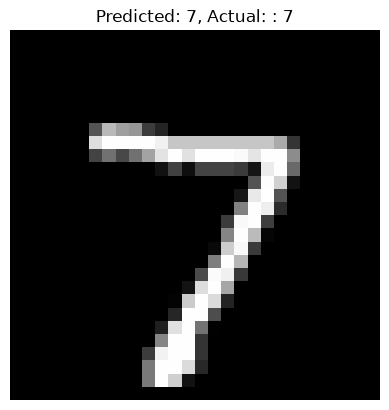

In [46]:
plt.imshow(
    x_test[0].squeeze(),
    cmap="gray"
)

plt.title(
    f"Predicted: {predicted_digit}, "
    f"Actual: : {y_test[0]}"
)

plt.axis("off")
plt.show()